# 02 Market overview

How big is the above-threshold public procurement market in Poland, what is bought and by whom.
Values are winning tender values in PLN (cleaned, see notebook 01).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

con = duckdb.connect("../data/tenders.duckdb", read_only=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)


def q(sql):
    return con.sql(sql).df()

In [2]:
q('''
SELECT year, count(*) AS lots, count(DISTINCT buyer_key) AS buyers,
       count(DISTINCT winner_key) AS winners, round(sum(value_pln) / 1e9, 1) AS value_bln
FROM fact_lot
GROUP BY 1
ORDER BY 1
''')

,year,lots,buyers,winners,value_bln
0,2024,57399,5112,13757,159.50
1,2025,81010,5462,17810,193.40
2,2026,69366,5112,16165,236.20


2026 is only January - October and it is already bigger than the whole 2025.

## What is bought

In [3]:
by_cat = q('''
SELECT d.division_name_en AS category, count(*) AS lots, sum(value_pln) / 1e9 AS value_bln
FROM fact_lot
JOIN dim_cpv d USING (cpv_division)
GROUP BY 1
ORDER BY value_bln DESC
LIMIT 12
''')
by_cat["category"] = by_cat["category"].str.slice(0, 45)
by_cat

,category,lots,value_bln
0,Construction work,5128,141.59
1,"Medical equipments, pharmaceuticals and perso",94615,87.45
2,"Sewage, refuse, cleaning and environmental se",15610,60.82
3,Transport equipment and auxiliary products to,7014,45.97
4,"Petroleum products, fuel, electricity and oth",5867,37.29
5,Repair and maintenance services,8493,25.16
6,Transport services (excl. Waste transport),2805,18.55
7,"IT services: consulting, software development",3257,15.66
8,Health and social work services,4730,14.84
9,"Business services: law, marketing, consulting",3119,12.25


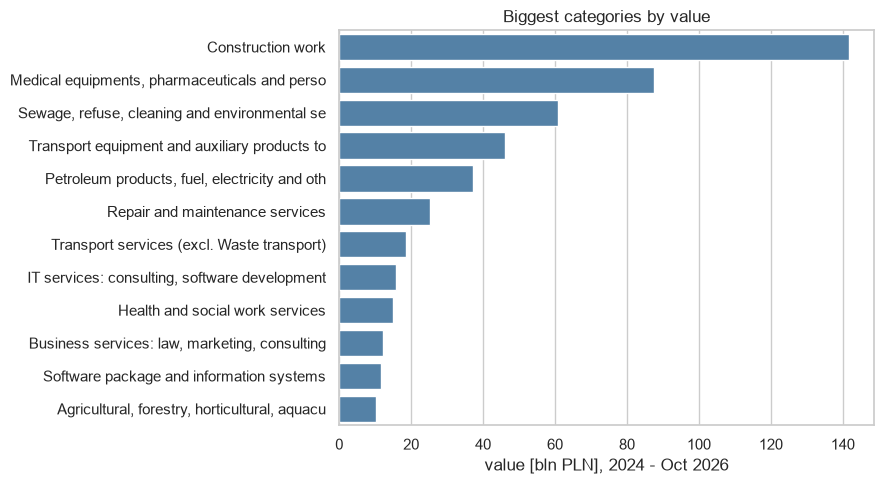

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=by_cat, y="category", x="value_bln", color="steelblue", ax=ax)
ax.set(xlabel="value [bln PLN], 2024 - Oct 2026", ylabel="", title="Biggest categories by value")
plt.tight_layout()
plt.savefig("../images/market_categories.png", dpi=120)

Construction has the biggest value but only ~5k lots. Medical supplies (CPV 33) is the opposite:
almost half of all lots, because hospitals split drug tenders into hundreds of small lots.

In [5]:
q('''
SELECT d.division_name_en AS category, count(*) AS lots,
       round(median(value_pln) / 1e3) AS median_value_k_pln
FROM fact_lot
JOIN dim_cpv d USING (cpv_division)
GROUP BY 1
ORDER BY lots DESC
LIMIT 5
''')

,category,lots,median_value_k_pln
0,"Medical equipments, pharmaceuticals and person...",94615,97.00
1,"Sewage, refuse, cleaning and environmental ser...",15610,897.00
2,Repair and maintenance services,8493,356.00
3,Transport equipment and auxiliary products to ...,7014,"1,057.00"
4,"Office and computing machinery, equipment and ...",6325,112.00


## Who buys

In [6]:
q('''
SELECT b.buyer_type, count(DISTINCT buyer_key) AS buyers, count(*) AS lots,
       round(sum(value_pln) / 1e9, 1) AS value_bln
FROM fact_lot
JOIN dim_buyer b USING (buyer_key)
GROUP BY 1
ORDER BY value_bln DESC
''')

,buyer_type,buyers,lots,value_bln
0,Public law body,4419,156023,310.90
1,Local government,3648,28069,113.40
2,Central government,463,11999,76.40
3,Public company,340,7500,62.40
4,Other,472,4184,26.00


"Public law body" is a wide group - hospitals, universities, agencies and state companies.
Top 10 buyers by value:

In [7]:
q('''
SELECT left(b.buyer_name, 60) AS buyer, b.buyer_type, count(*) AS lots,
       round(sum(value_pln) / 1e9, 2) AS value_bln
FROM fact_lot
JOIN dim_buyer b USING (buyer_key)
GROUP BY ALL
ORDER BY value_bln DESC
LIMIT 10
''')

,buyer,buyer_type,lots,value_bln
0,Generalna Dyrekcja Dróg Krajowych i Autostrad,Central government,965,32.09
1,PKP Polskie Linie Kolejowe S.A.,Public company,490,16.19
2,25. Wojskowy Oddział Gospodarczy w Białymstoku.,Public law body,159,14.73
3,Ministerstwo Obrony Narodowej,Central government,445,6.62
4,"""PKP Intercity"" S.A.",Public law body,200,6.45
5,PGE Dystrybucja S.A.,Public company,700,6.04
6,Narodowy Instytut Onkologii im. Marii Skłodows...,Public law body,1575,5.04
7,Polska Grupa Górnicza S.A.,Public law body,1233,5.04
8,"""Koleje Mazowieckie - KM"" sp. z o.o.",Public law body,75,5.03
9,Jastrzębska Spółka Węglowa S.A. z siedzibą w J...,Other,885,4.92


## Where

In [8]:
by_region = q('''
SELECT r.voivodeship, count(*) AS lots, sum(value_pln) / 1e9 AS value_bln
FROM fact_lot
JOIN dim_region r USING (nuts2)
WHERE r.voivodeship NOT IN ('Unknown', 'Whole country')
GROUP BY 1
ORDER BY value_bln DESC
''')
by_region

,voivodeship,lots,value_bln
0,Mazowieckie,36560,128.58
1,Śląskie,22374,50.19
2,Małopolskie,16195,37.91
3,Dolnośląskie,14017,37.64
4,Pomorskie,13843,35.97
5,Wielkopolskie,14363,32.48
6,Łódzkie,9989,28.23
7,Podlaskie,6158,24.63
8,Zachodniopomorskie,7983,23.96
9,Lubelskie,10750,21.71


## When

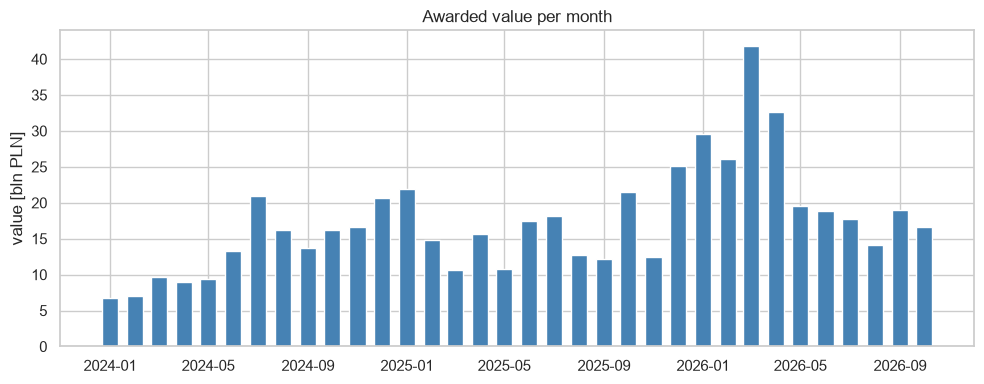

In [9]:
monthly = q('''
SELECT publication_month AS month, count(*) AS lots, sum(value_pln) / 1e9 AS value_bln
FROM fact_lot
GROUP BY 1
ORDER BY 1
''')
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly["month"], monthly["value_bln"], width=20, color="steelblue")
ax.set(ylabel="value [bln PLN]", title="Awarded value per month")
plt.tight_layout()

In [10]:
# only full years for seasonality
q('''
SELECT month(publication_date) AS month, count(*) AS lots, round(sum(value_pln) / 1e9, 1) AS value_bln
FROM fact_lot
WHERE year IN (2024, 2025)
GROUP BY 1
ORDER BY 1
''')

,month,lots,value_bln
0,1,12131,28.70
1,2,9240,21.90
2,3,9595,20.30
3,4,9598,24.60
4,5,8808,20.20
5,6,10830,30.70
6,7,11935,39.10
7,8,11135,29.00
8,9,12079,25.80
9,10,15003,37.80


## Summary

- around 160-240 bln PLN a year is awarded in above-threshold tenders
- construction, medical supplies, waste/cleaning, transport equipment and energy are the biggest categories
- medical supplies are a market of many small lots, construction of few large ones
- Mazowieckie is the biggest region by far (central institutions are in Warsaw)
- December and October are the busiest months, end of the budget year is visible